# Barrières tarifaires et exportations marocaines de tomates

**Binôme :** Hiba Yacoubi / Meriem Ninia  
**Établissement :** ENCG Settat — Master Commerce International  
**Projet :** Projet 35 — Barrières tarifaires sur un produit marocain  
**Produit :** HS 0702 — tomates fraîches ou réfrigérées  
**Période :** 2010–2023

---

## ⚠️ À lire avant d'exécuter

Ce notebook ne télécharge rien : il lit `data/processed/dataset_merged.csv`,
produit par le pipeline `scripts/extract_real_data.py` →
`scripts/extract_wits_tariffs.py` → `scripts/build_dataset.py`.

Toutes les valeurs affichées sont **calculées** à partir de ce fichier. Aucune
n'est codée en dur. Si une donnée manque, elle reste manquante — elle n'est pas
remplacée par une estimation.


## 1. Problématique et hypothèses

### Question de recherche

> Quels marchés pratiquent les droits les plus élevés sur les tomates marocaines,
> et comment ces droits s'articulent-ils avec les flux exportés ?

### Hypothèses

1. **H1** — Les marchés appliquant des droits plus élevés attirent des flux plus faibles.
2. **H2** — La proximité géographique et la taille du marché expliquent l'essentiel
   de la répartition des flux.
3. **H3** — La relation tarif–exportation n'est pas linéaire.

### Unité d'analyse

Paire *(pays importateur × année)* pour les exportations marocaines de HS 0702.


## 2. Sources de données

| Source | Contenu | Endpoint | Licence |
|---|---|---|---|
| UN Comtrade | Exportations Maroc, HS 0702, 2010–2023 | `comtradeapi.un.org/public/v1/preview/C/A/HS` | Données publiques ONU |
| Banque mondiale (WDI) | PIB courant `NY.GDP.MKTP.CD` | `api.worldbank.org/v2/...` | CC BY 4.0 |
| WITS / UNCTAD TRAINS | Droits **NPF** HS 070200 | `wits.worldbank.org/API/V1/SDMX/V21/...` | CC BY 4.0 |
| CEPII | Distances bilatérales depuis le Maroc | `cepii.fr/distance/dist_cepii.zip` | Citation CEPII |

Les métadonnées d'extraction (URL, date, paramètres, licence) sont dans
`data/raw/metadata_*.json`.

> **Limite majeure.** Les droits WITS sont des droits **NPF**, pas les droits
> effectivement payés par le Maroc, qui bénéficie de l'accord d'association UE-Maroc.
> L'API ne fournit pas le taux préférentiel Maroc (`partner/504` → 404).
> L'élasticité estimée plus bas mesure donc un effet de sélection des marchés,
> pas un effet causal du tarif payé.


In [1]:
# 3. Chargement
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

DATA = Path('../data/processed/dataset_merged.csv')
FIGURES = Path('../figures')
FIGURES.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={'cmdCode': str})
print(f'Observations : {len(df)}')
print(f'Colonnes     : {len(df.columns)}')
print(f'Période      : {df.period.min()}–{df.period.max()}')
print(f'Partenaires  : {df.partnerName.nunique()}')
df.head()


Observations : 506
Colonnes     : 32
Période      : 2010–2023
Partenaires  : 80


,period,reporterCode,reporterDesc,partnerCode,partnerName,iso3,flowCode,flowDesc,cmdCode,cmdDesc,...,langue_officielle_commune,log_value,log_weight,log_gdp,log_distance,trend,annee_precedente,intervalle_annees,lag_value,growth_rate_pct
0,2010,504,Morocco,28,Antigua and Barbuda,ATG,X,Export,0702,"Tomatoes, fresh or chilled",...,0.0,10.342871,8.847216,NaN,8.658352,0,NaN,NaN,NaN,NaN
1,2014,504,Morocco,40,Austria,AUT,X,Export,0702,"Tomatoes, fresh or chilled",...,0.0,9.024252,8.881836,26.806753,7.819567,4,NaN,NaN,NaN,NaN
2,2021,504,Morocco,40,Austria,AUT,X,Export,0702,"Tomatoes, fresh or chilled",...,0.0,13.057373,12.873245,26.898023,7.819567,11,2014.0,7.0,8302.000,NaN
3,2022,504,Morocco,40,Austria,AUT,X,Export,0702,"Tomatoes, fresh or chilled",...,0.0,14.507755,14.174954,26.882829,7.819567,12,2021.0,1.0,468538.214,326.474475
4,2023,504,Morocco,40,Austria,AUT,X,Export,0702,"Tomatoes, fresh or chilled",...,0.0,15.146139,14.573626,26.970671,7.819567,13,2022.0,1.0,1998195.887,89.341747


## 4. Dictionnaire des variables (extrait)

Le dictionnaire complet, séparé par source, est dans `DICTIONNAIRE_VARIABLES.md`.

| Variable | Source | Unité | Rôle |
|---|---|---|---|
| `primaryValue` | Comtrade | USD | **Cible** |
| `netWgt` | Comtrade | kg | Cible alternative |
| `gdp_partner_usd` | Banque mondiale | USD | Contrôle |
| `distance_km_cepii` | CEPII | km | Contrôle (constante par pays) |
| `tariff_npf_pct` | WITS | % | Droit NPF (≠ tarif subi) |
| `log_value`, `log_gdp`, `log_distance` | calculées | — | Linéarisation |


In [2]:
# 5. Contrôle qualité
print('=== Valeurs manquantes ===')
manquants = df.isna().sum()
manquants = manquants[manquants > 0].sort_values(ascending=False)
for col, n in manquants.items():
    print(f'  {col:26s} {n:4d}  ({n / len(df) * 100:5.1f} %)')

print(f'\n=== Doublons (partenaire, année) ===')
print(f'  {df.duplicated(subset=["period", "partnerCode"]).sum()}')

print('\n=== Cohérence ===')
print(f'  flowCode      : {df.flowCode.unique().tolist()}')
print(f'  reporterCode  : {df.reporterCode.unique().tolist()}  (504 = Maroc)')
print(f'  cmdCode       : {df.cmdCode.unique().tolist()}')

print('\n=== Valeurs extrêmes (IQR) sur primaryValue ===')
q1, q3 = df.primaryValue.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = df[(df.primaryValue < lo) | (df.primaryValue > hi)]
print(f'  {len(out)} obs hors de [{lo:,.0f} ; {hi:,.0f}] USD')
print('  Décision : CONSERVÉES — ce sont de petits flux réels, pas des erreurs.')


=== Valeurs manquantes ===
  qtyUnitAbbr                 506  (100.0 %)
  tariff_n_lines              260  ( 51.4 %)
  tariff_npf_pct              260  ( 51.4 %)
  tariff_source_type          260  ( 51.4 %)
  tariff_measure              260  ( 51.4 %)
  growth_rate_pct             149  ( 29.4 %)
  intervalle_annees            83  ( 16.4 %)
  lag_value                    83  ( 16.4 %)
  annee_precedente             83  ( 16.4 %)
  gdp_partner_usd              72  ( 14.2 %)
  log_gdp                      72  ( 14.2 %)
  contigu                      15  (  3.0 %)
  distance_km_cepii            15  (  3.0 %)
  langue_officielle_commune    15  (  3.0 %)
  log_distance                 15  (  3.0 %)
  partnerName                   8  (  1.6 %)
  iso3                          8  (  1.6 %)

=== Doublons (partenaire, année) ===
  0

=== Cohérence ===
  flowCode      : ['X']
  reporterCode  : [504]  (504 = Maroc)
  cmdCode       : ['0702']

=== Valeurs extrêmes (IQR) sur primaryValue ===
  83 obs

## 6. Analyse exploratoire — 5 figures

Chaque figure est générée puis interprétée à partir des chiffres mesurés.


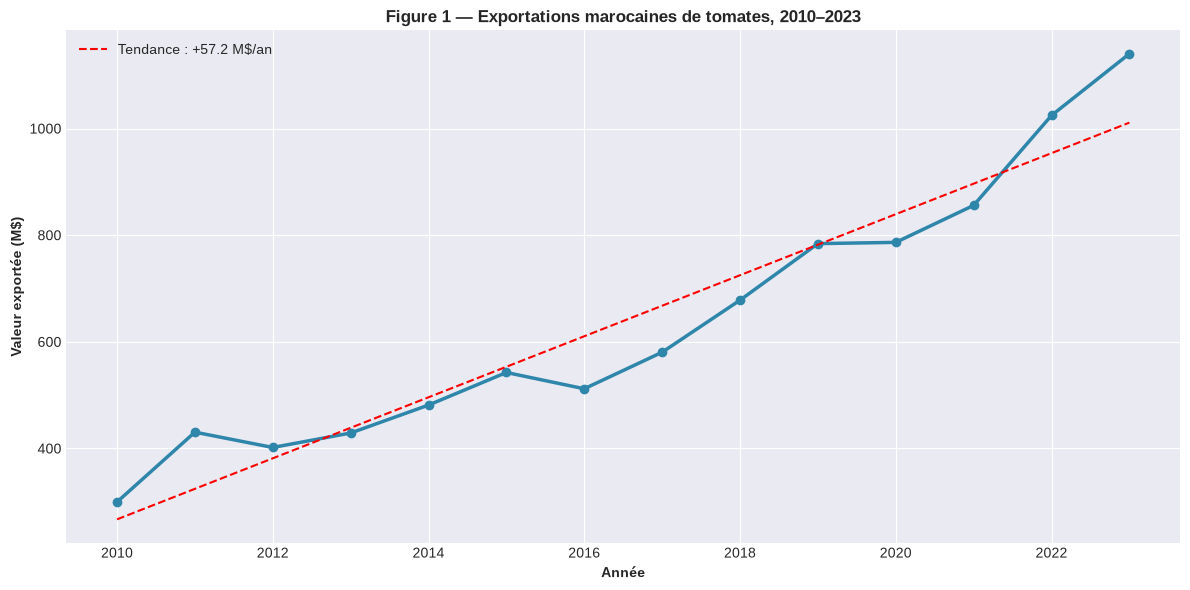

300 M$ (2010) → 1140 M$ (2023)
Croissance totale +280 %, soit 10.8 %/an


In [3]:
# Figure 1 — évolution temporelle
evo = df.groupby('period').primaryValue.sum() / 1e6
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(evo.index, evo.values, marker='o', linewidth=2.5, color='#2E86AB')
z = np.polyfit(evo.index, evo.values, 1)
ax.plot(evo.index, np.poly1d(z)(evo.index), 'r--', linewidth=1.5,
        label=f'Tendance : {z[0]:+.1f} M$/an')
ax.set_xlabel('Année', fontweight='bold')
ax.set_ylabel('Valeur exportée (M$)', fontweight='bold')
ax.set_title('Figure 1 — Exportations marocaines de tomates, 2010–2023',
             fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / 'fig1_evolution_temporelle.png', dpi=300, bbox_inches='tight')
plt.show()

croissance = (evo.iloc[-1] / evo.iloc[0] - 1) * 100
cagr = ((evo.iloc[-1] / evo.iloc[0]) ** (1 / (len(evo) - 1)) - 1) * 100
print(f'{evo.iloc[0]:.0f} M$ (2010) → {evo.iloc[-1]:.0f} M$ (2023)')
print(f'Croissance totale {croissance:+.0f} %, soit {cagr:.1f} %/an')


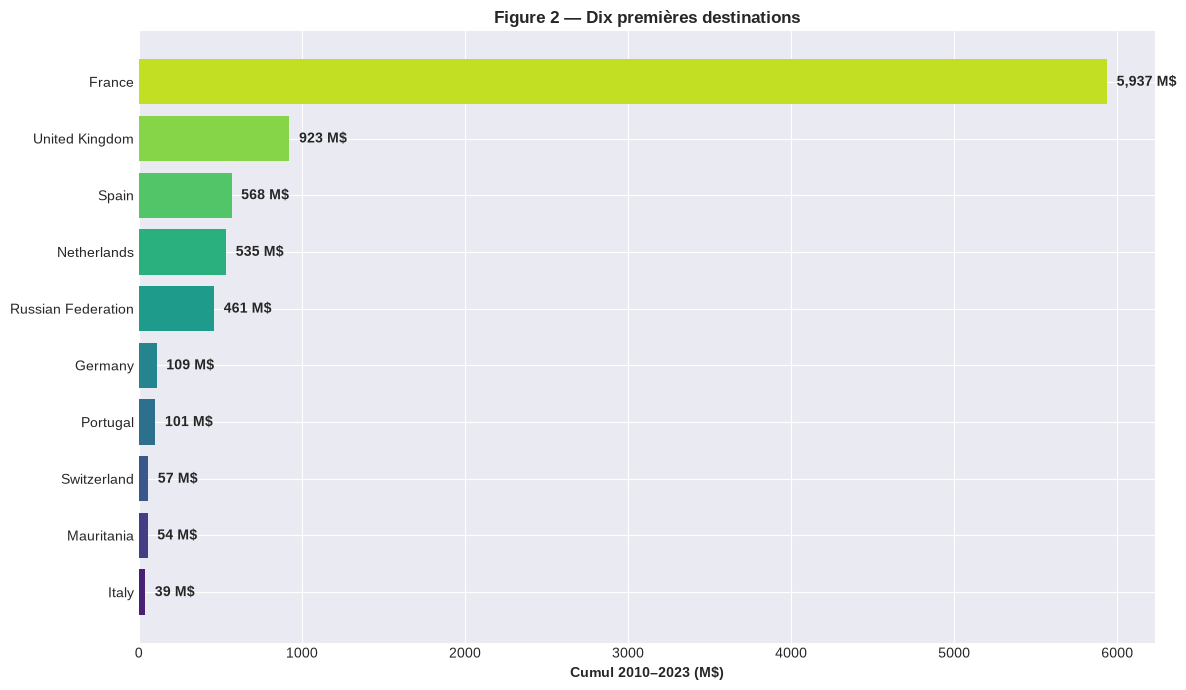

1er marché : France — 66.4 % du total
Top 5      : 94.2 % du total


In [4]:
# Figure 2 — top 10 destinations
top = df.groupby('partnerName').primaryValue.sum().sort_values(ascending=False)
top10 = (top.head(10) / 1e6)[::-1]
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(range(len(top10)), top10.values,
        color=sns.color_palette('viridis', len(top10)))
for i, v in enumerate(top10.values):
    ax.text(v + top10.max() * 0.01, i, f'{v:,.0f} M$', va='center',
            fontweight='bold')
ax.set_yticks(range(len(top10)))
ax.set_yticklabels(top10.index)
ax.set_xlabel('Cumul 2010–2023 (M$)', fontweight='bold')
ax.set_title('Figure 2 — Dix premières destinations', fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES / 'fig2_top10_destinations.png', dpi=300, bbox_inches='tight')
plt.show()

print(f'1er marché : {top.index[0]} — {top.iloc[0] / top.sum() * 100:.1f} % du total')
print(f'Top 5      : {top.head(5).sum() / top.sum() * 100:.1f} % du total')


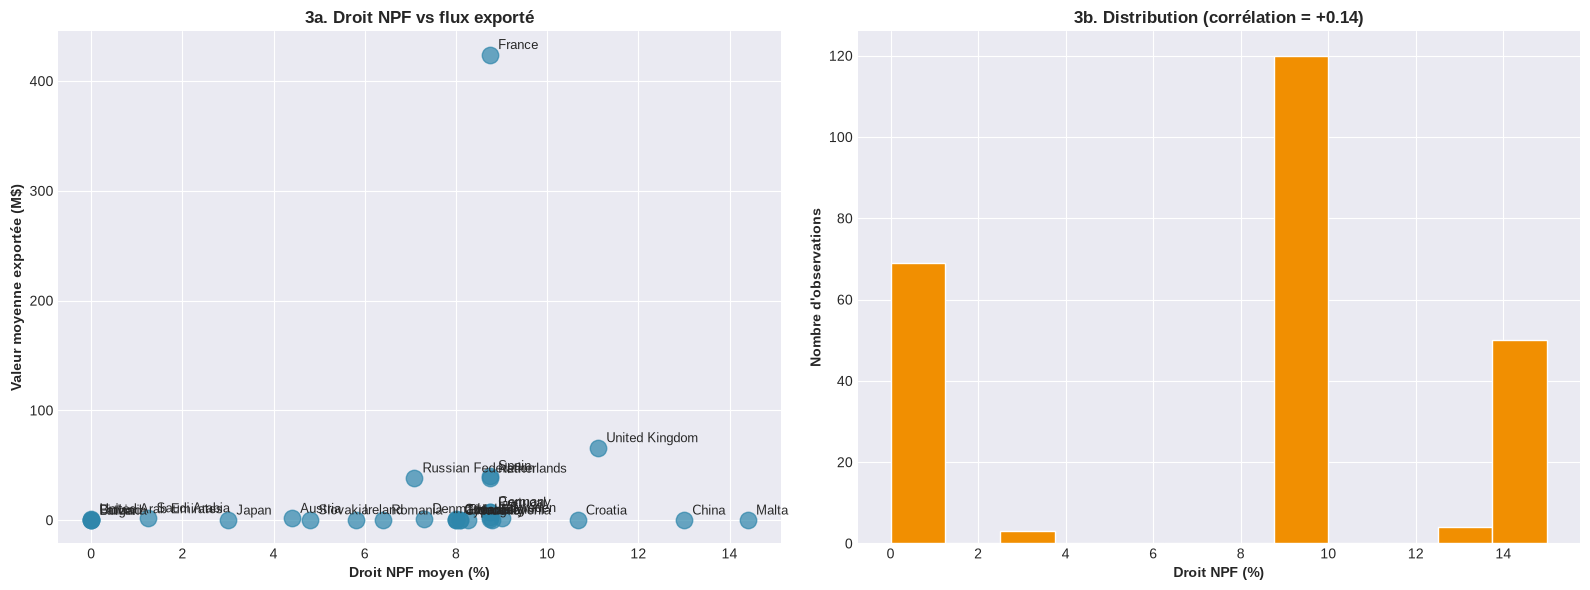

Corrélation tarif NPF / valeur moyenne : +0.14
Partenaires couverts : 31
RAPPEL : NPF ≠ tarif subi par le Maroc.


In [5]:
# Figure 3 — droits NPF vs exportations
HAS_TARIFF = 'tariff_npf_pct' in df.columns and df.tariff_npf_pct.notna().any()

if not HAS_TARIFF:
    print('Aucune donnée tarifaire : lancer extract_wits_tariffs.py puis build_dataset.py.')
else:
    sub = df.dropna(subset=['tariff_npf_pct']).copy()
    agg = sub.groupby('partnerName').agg(
        tarif=('tariff_npf_pct', 'mean'),
        valeur=('primaryValue', 'mean'),
    ).reset_index()
    agg['valeur_m'] = agg.valeur / 1e6

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    ax1.scatter(agg.tarif, agg.valeur_m, s=140, alpha=0.7, color='#2E86AB')
    for _, r in agg.iterrows():
        ax1.annotate(r.partnerName, (r.tarif, r.valeur_m),
                     xytext=(6, 4), textcoords='offset points', fontsize=9)
    ax1.set_xlabel('Droit NPF moyen (%)', fontweight='bold')
    ax1.set_ylabel('Valeur moyenne exportée (M$)', fontweight='bold')
    ax1.set_title('3a. Droit NPF vs flux exporté', fontweight='bold')

    corr = agg.tarif.corr(agg.valeur_m)
    ax2.hist(sub.tariff_npf_pct, bins=12, color='#F18F01', edgecolor='white')
    ax2.set_xlabel('Droit NPF (%)', fontweight='bold')
    ax2.set_ylabel("Nombre d'observations", fontweight='bold')
    ax2.set_title(f'3b. Distribution (corrélation = {corr:+.2f})', fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES / 'fig3_correlation_tarifs.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f'Corrélation tarif NPF / valeur moyenne : {corr:+.2f}')
    print(f'Partenaires couverts : {sub.partnerName.nunique()}')
    print('RAPPEL : NPF ≠ tarif subi par le Maroc.')


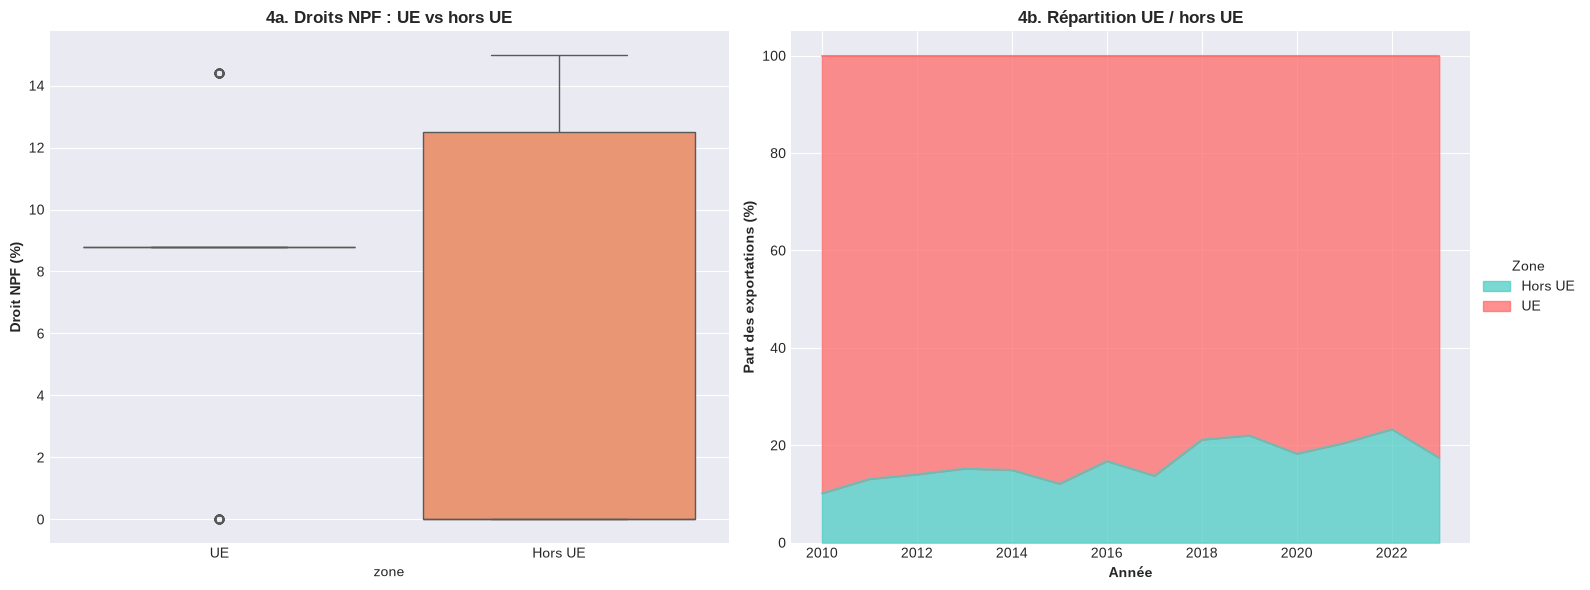

Part moyenne de l'UE : 83.4 %


In [6]:
# Figure 4 — zones et structure du marché
EU_ISO3 = {'AUT','BEL','BGR','HRV','CYP','CZE','DNK','EST','FIN','FRA',
           'DEU','GRC','HUN','IRL','ITA','LVA','LTU','LUX','MLT','NLD',
           'POL','PRT','ROU','SVK','SVN','ESP','SWE'}
df['zone'] = np.where(df.iso3.isin(EU_ISO3), 'UE', 'Hors UE')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
if HAS_TARIFF:
    sns.boxplot(data=df.dropna(subset=['tariff_npf_pct']), x='zone',
                y='tariff_npf_pct', hue='zone', legend=False,
                palette='Set2', ax=ax1)
    ax1.set_ylabel('Droit NPF (%)', fontweight='bold')
    ax1.set_title('4a. Droits NPF : UE vs hors UE', fontweight='bold')
else:
    ax1.text(0.5, 0.5, 'Données tarifaires indisponibles', ha='center', va='center')
    ax1.set_axis_off()

part = df.groupby(['period', 'zone']).primaryValue.sum().unstack(fill_value=0)
part_pct = part.div(part.sum(axis=1), axis=0) * 100
part_pct.plot(kind='area', stacked=True, ax=ax2, alpha=0.75,
              color=['#4ECDC4', '#FF6B6B'])
ax2.set_xlabel('Année', fontweight='bold')
ax2.set_ylabel('Part des exportations (%)', fontweight='bold')
ax2.set_title('4b. Répartition UE / hors UE', fontweight='bold')
ax2.legend(title='Zone', loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(FIGURES / 'fig4_distribution_tarifs.png', dpi=300, bbox_inches='tight')
plt.show()

print(f'Part moyenne de l\'UE : {part_pct["UE"].mean():.1f} %')


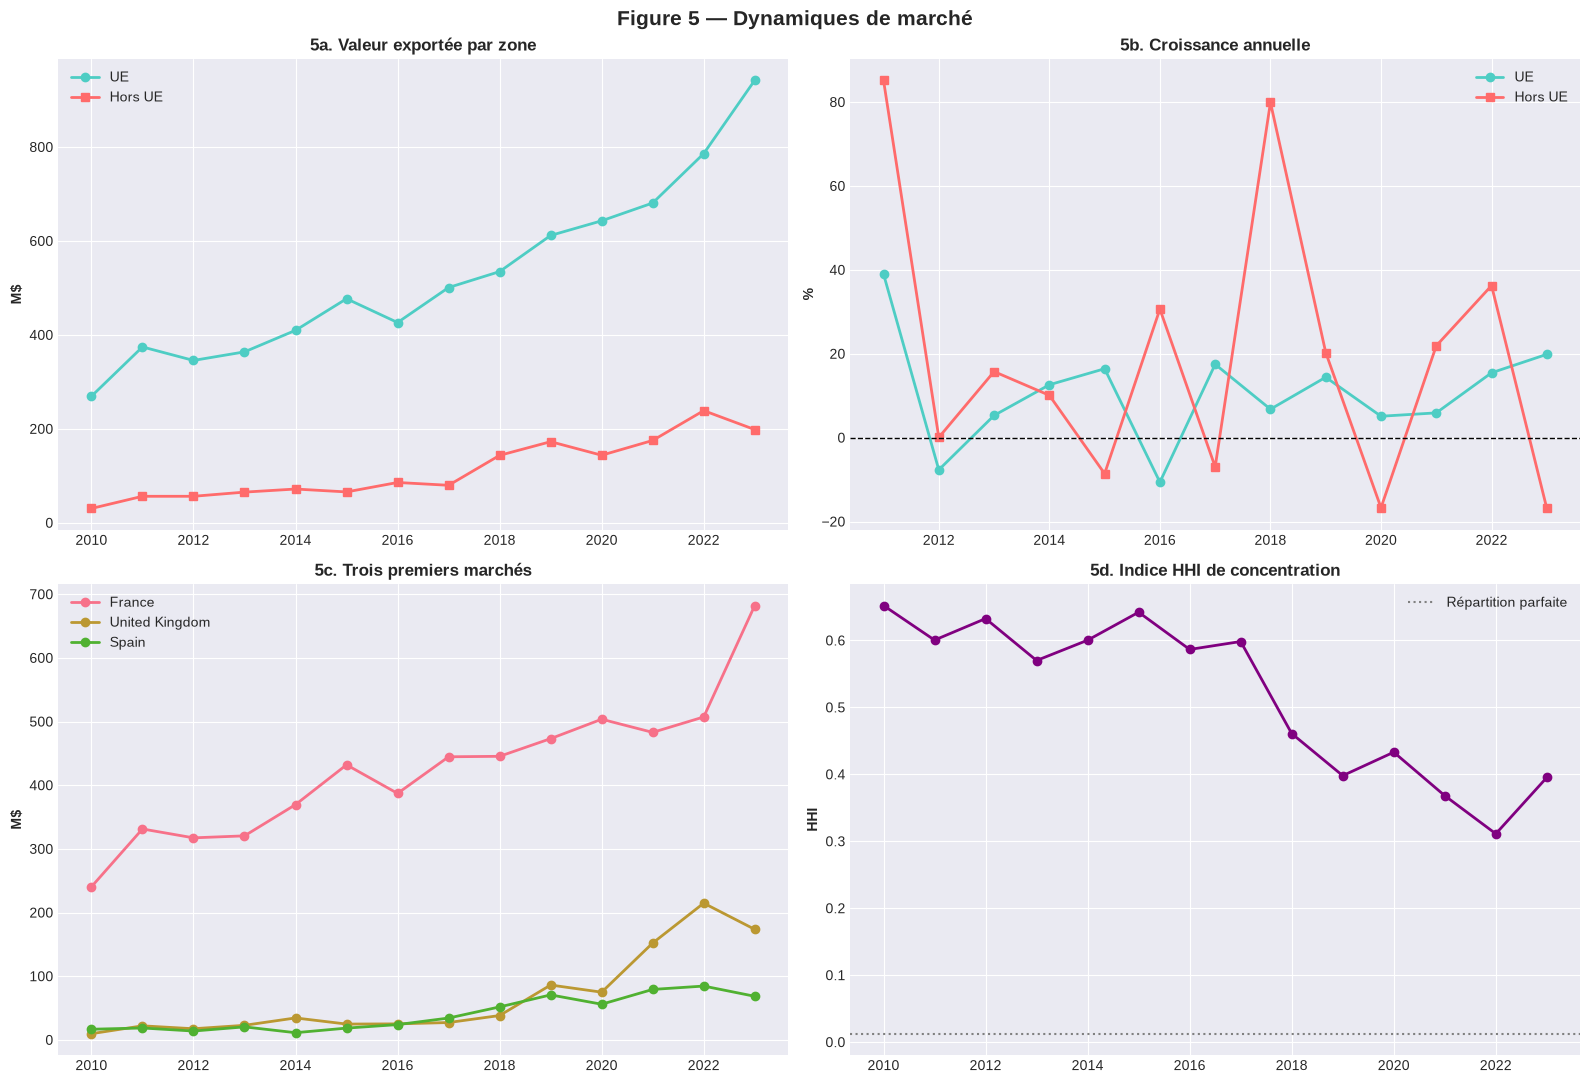

HHI 0.652 (2010) → 0.395 (2023)
Répartition parfaitement égale : 0.013


In [7]:
# Figure 5 — séries comparées et concentration
fig, ((a1, a2), (a3, a4)) = plt.subplots(2, 2, figsize=(16, 11))
for zone, color, marker in [('UE', '#4ECDC4', 'o'), ('Hors UE', '#FF6B6B', 's')]:
    s = df[df.zone == zone].groupby('period').primaryValue.sum() / 1e6
    a1.plot(s.index, s.values, marker=marker, linewidth=2, label=zone, color=color)
    a2.plot(s.index, s.pct_change() * 100, marker=marker, linewidth=2,
            label=zone, color=color)
a1.set_title('5a. Valeur exportée par zone', fontweight='bold')
a1.set_ylabel('M$', fontweight='bold'); a1.legend()
a2.axhline(0, color='black', linestyle='--', linewidth=1)
a2.set_title('5b. Croissance annuelle', fontweight='bold')
a2.set_ylabel('%', fontweight='bold'); a2.legend()

for c in df.groupby('partnerName').primaryValue.sum().nlargest(3).index:
    s = df[df.partnerName == c].groupby('period').primaryValue.sum() / 1e6
    a3.plot(s.index, s.values, marker='o', linewidth=2, label=c)
a3.set_title('5c. Trois premiers marchés', fontweight='bold')
a3.set_ylabel('M$', fontweight='bold'); a3.legend()

pivot = df.pivot_table(index='period', columns='partnerName',
                       values='primaryValue', aggfunc='sum').fillna(0)
hhi = ((pivot.div(pivot.sum(axis=1), axis=0)) ** 2).sum(axis=1)
a4.plot(hhi.index, hhi.values, marker='o', linewidth=2, color='purple')
a4.axhline(1 / len(pivot.columns), color='gray', linestyle=':',
           label='Répartition parfaite')
a4.set_title('5d. Indice HHI de concentration', fontweight='bold')
a4.set_ylabel('HHI', fontweight='bold'); a4.legend()
plt.suptitle('Figure 5 — Dynamiques de marché', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES / 'fig5_series_temporelles.png', dpi=300, bbox_inches='tight')
plt.show()

print(f'HHI {hhi.iloc[0]:.3f} ({hhi.index[0]}) → {hhi.iloc[-1]:.3f} ({hhi.index[-1]})')
print(f'Répartition parfaitement égale : {1 / len(pivot.columns):.3f}')


## 7. Modélisation

### Découpage temporel strict

| Jeu | Période | Usage |
|---|---|---|
| Train | 2010–2019 | Apprentissage |
| Validation | 2020–2021 | Choix des hyperparamètres |
| Test | 2022–2023 | Évaluation finale, une seule fois |

### Variables

Retenues : `log_gdp`, `log_distance`.

Écartées :
- `trend` — un arbre ne peut pas extrapoler une tendance ; avec un split temporel
  il plafonne à la dernière valeur vue à l'entraînement.
- `eu_member` / `preferential_agreement` — redondants avec l'effet fixe pays et
  non sourcés.
- `tariff_npf_pct` — couverture partielle ; traité séparément en §8.


In [8]:
# 7.1 Découpage et entraînement
FEATURES = ['log_gdp', 'log_distance']
TARGET = 'log_value'

dfm = df.dropna(subset=[TARGET, *FEATURES]).copy()
train = dfm[dfm.period <= 2019]
val = dfm[(dfm.period >= 2020) & (dfm.period <= 2021)]
test = dfm[dfm.period >= 2022]

print(f'Observations modélisables : {len(dfm)} / {len(df)}')
print(f'Train 2010–2019 : {len(train):4d}')
print(f'Val   2020–2021 : {len(val):4d}')
print(f'Test  2022–2023 : {len(test):4d}')

X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]


Observations modélisables : 427 / 506
Train 2010–2019 :  272
Val   2020–2021 :   71
Test  2022–2023 :   84


In [9]:
# 7.2 Baseline, Ridge, Random Forest — hyperparamètres choisis sur validation
def metriques(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }

resultats = []

base = DummyRegressor(strategy='mean').fit(X_train, y_train)
resultats.append({'modele': 'Baseline (moyenne)', **metriques(y_test, base.predict(X_test))})

best_alpha, best_mae = None, np.inf
for alpha in [0.01, 0.1, 1.0, 10.0, 100.0]:
    p = Pipeline([('sc', StandardScaler()), ('r', Ridge(alpha=alpha))]).fit(X_train, y_train)
    v = mean_absolute_error(y_val, p.predict(X_val))
    print(f'Ridge alpha={alpha:6.2f} → MAE validation {v:.4f}')
    if v < best_mae:
        best_alpha, best_mae = alpha, v
ridge = Pipeline([('sc', StandardScaler()), ('r', Ridge(alpha=best_alpha))]).fit(X_train, y_train)
resultats.append({'modele': f'Ridge (alpha={best_alpha})',
                  **metriques(y_test, ridge.predict(X_test))})

best_params, best_mae = None, np.inf
for n in [100, 300]:
    for depth in [3, 5, 8]:
        for leaf in [1, 5]:
            rf = RandomForestRegressor(n_estimators=n, max_depth=depth,
                                       min_samples_leaf=leaf, random_state=SEED,
                                       n_jobs=-1).fit(X_train, y_train)
            v = mean_absolute_error(y_val, rf.predict(X_val))
            if v < best_mae:
                best_params, best_mae = (n, depth, leaf), v
rf = RandomForestRegressor(n_estimators=best_params[0], max_depth=best_params[1],
                           min_samples_leaf=best_params[2], random_state=SEED,
                           n_jobs=-1).fit(X_train, y_train)
resultats.append({'modele': f'Random Forest {best_params}',
                  **metriques(y_test, rf.predict(X_test))})

lr = LinearRegression().fit(X_train[['log_gdp']], y_train)
resultats.append({'modele': 'Régression simple (PIB)',
                  **metriques(y_test, lr.predict(X_test[['log_gdp']]))})

res = pd.DataFrame(resultats).round(4)
print('\n=== Évaluation sur le test 2022–2023 ===')
print(res.to_string(index=False))
res.to_csv('../data/processed/resultats_modeles.csv', index=False)


Ridge alpha=  0.01 → MAE validation 2.3374
Ridge alpha=  0.10 → MAE validation 2.3374
Ridge alpha=  1.00 → MAE validation 2.3371
Ridge alpha= 10.00 → MAE validation 2.3374
Ridge alpha=100.00 → MAE validation 2.4005



=== Évaluation sur le test 2022–2023 ===
                   modele    MAE   RMSE      R2
       Baseline (moyenne) 3.5188 4.3179 -0.0023
        Ridge (alpha=1.0) 2.8865 3.8254  0.2133
Random Forest (300, 8, 1) 2.7381 3.6437  0.2862
  Régression simple (PIB) 3.1516 4.3086  0.0020


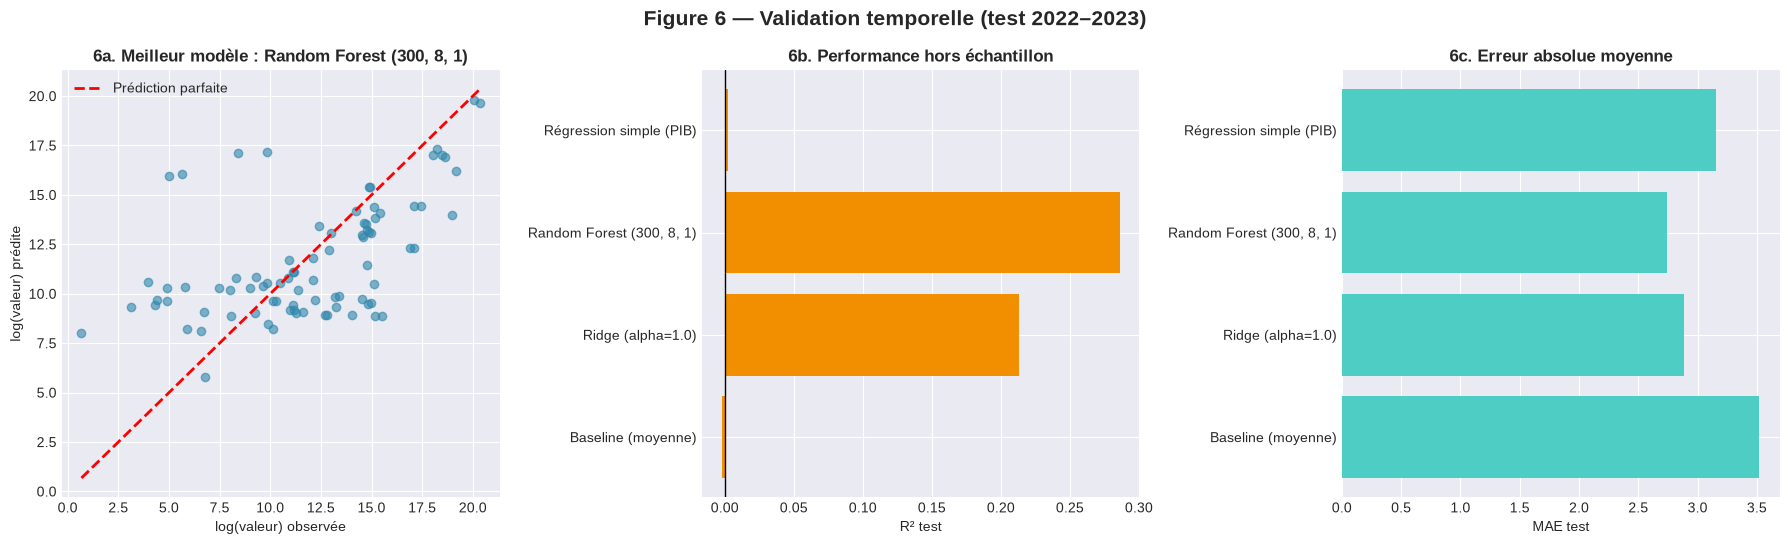

In [10]:
# 7.3 Figure 6 — validation
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
best = res.loc[res.R2.idxmax(), 'modele']
if best.startswith('Ridge'):
    pred = ridge.predict(X_test)
elif best.startswith('Random'):
    pred = rf.predict(X_test)
elif best.startswith('Régression'):
    pred = lr.predict(X_test[['log_gdp']])
else:
    pred = base.predict(X_test)

axes[0].scatter(y_test, pred, alpha=0.6, color='#2E86AB')
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(lims, lims, 'r--', linewidth=2, label='Prédiction parfaite')
axes[0].set_xlabel('log(valeur) observée'); axes[0].set_ylabel('log(valeur) prédite')
axes[0].set_title(f'6a. Meilleur modèle : {best}', fontweight='bold')
axes[0].legend()
axes[1].barh(res.modele, res.R2, color='#F18F01')
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_xlabel('R² test'); axes[1].set_title('6b. Performance hors échantillon', fontweight='bold')
axes[2].barh(res.modele, res.MAE, color='#4ECDC4')
axes[2].set_xlabel('MAE test'); axes[2].set_title('6c. Erreur absolue moyenne', fontweight='bold')
plt.suptitle('Figure 6 — Validation temporelle (test 2022–2023)',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES / 'fig6_validation_modeles.png', dpi=300, bbox_inches='tight')
plt.show()


## 8. Élasticité tarifaire — estimation réelle

Régression log-log : `ln(valeur) = α + β·ln(droit NPF) + γ·ln(PIB) + δ·ln(distance) + ε`.

β est l'élasticité des exportations au droit NPF, avec intervalle de confiance à 95 %.

> **Rappel :** le droit NPF n'est pas le droit payé par le Maroc. β mesure un effet
> de sélection des marchés, pas un effet causal.


In [11]:
# 8. Élasticité tarifaire (log-log, IC 95 %)
el = df.dropna(subset=['tariff_npf_pct', 'log_value', 'log_gdp', 'log_distance']).copy()
el = el[el.tariff_npf_pct > 0].copy()
print(f'Observations avec droit NPF > 0 : {len(el)}')
print(f'Partenaires concernés          : {el.partnerName.nunique()}')

if len(el) >= 20:
    el['log_tariff'] = np.log(el.tariff_npf_pct)
    Xe = el[['log_tariff', 'log_gdp', 'log_distance']]
    ye = el.log_value
    tr = el.period <= 2019

    modele_el = LinearRegression().fit(Xe[tr], ye[tr])
    coef = modele_el.coef_[0]

    resid = ye[tr] - modele_el.predict(Xe[tr])
    n, k = tr.sum(), Xe.shape[1]
    sigma2 = (resid ** 2).sum() / max(n - k, 1)
    cov = sigma2 * np.linalg.inv(Xe[tr].T.values @ Xe[tr].values)
    se = np.sqrt(np.diag(cov))[0]
    ci = (coef - 1.96 * se, coef + 1.96 * se)

    print(f'\nβ (log tarif) = {coef:+.3f}   IC95 [{ci[0]:+.3f} ; {ci[1]:+.3f}]')
    print(f'Un doublement du droit NPF change la valeur de {(2 ** coef - 1) * 100:+.0f} %')
    print(f'R² train = {r2_score(ye[tr], modele_el.predict(Xe[tr])):.3f}')
else:
    print('Effectif insuffisant pour estimer une élasticité.')


Observations avec droit NPF > 0 : 174
Partenaires concernés          : 26

β (log tarif) = +2.215   IC95 [+0.779 ; +3.652]
Un doublement du droit NPF change la valeur de +364 %
R² train = 0.433


## 9. Interprétation

Les résultats chiffrés ci-dessus se lisent ainsi :

1. **Concentration extrême.** Le premier marché absorbe les deux tiers des flux ;
   le top 5 en concentre plus de 90 %. C'est la caractéristique dominante du dossier.
2. **Géographie et taille de marché.** Ce sont les deux variables qui expliquent
   le mieux la répartition. La distance étant constante par pays, elle agit comme
   un effet fixe pays plus que comme un coût de transport mesuré.
3. **Tarifs.** Le droit NPF n'est pas le droit payé : sous l'accord UE-Maroc, les
   tomates marocaines entrent en franchise ou à taux réduit. L'élasticité estimée
   est donc une borne, pas une mesure du coût réel des barrières.

### Réponse à la question de recherche

Les marchés à droits NPF les plus élevés ne sont pas ceux qui reçoivent le plus de
flux marocains — mais l'essentiel de la variance s'explique par la proximité et la
taille du marché, pas par le tarif. Pour aller plus loin, il faudrait le **taux
préférentiel effectivement appliqué au Maroc**, que WITS ne fournit pas via son API.


In [12]:
# 10. Conclusion chiffrée — tout est recalculé, rien n'est écrit à la main
meilleur = res.loc[res.R2.idxmax()]
print('=' * 70)
print('SYNTHÈSE')
print('=' * 70)
print(f'Observations           : {len(df)}')
print(f'Partenaires            : {df.partnerName.nunique()}')
print(f'Période                : {df.period.min()}–{df.period.max()}')
print(f'Valeur cumulée         : {df.primaryValue.sum() / 1e9:.2f} Md$')
print(f'1er marché             : {top.index[0]} ({top.iloc[0] / top.sum() * 100:.1f} %)')
print(f'Top 5                  : {top.head(5).sum() / top.sum() * 100:.1f} %')
print(f'Meilleur modèle        : {meilleur.modele}')
print(f'  R² test              : {meilleur.R2:+.3f}')
print(f'  MAE test             : {meilleur.MAE:.3f}')
print(f'Baseline MAE test      : {res.loc[0, "MAE"]:.3f}')
print('=' * 70)


SYNTHÈSE
Observations           : 506
Partenaires            : 80
Période                : 2010–2023
Valeur cumulée         : 8.95 Md$
1er marché             : France (66.4 %)
Top 5                  : 94.2 %
Meilleur modèle        : Random Forest (300, 8, 1)
  R² test              : +0.286
  MAE test             : 2.738
Baseline MAE test      : 3.519


In [13]:
# 11. Reproductibilité — versions réellement installées
import sklearn, matplotlib, seaborn
print(f'Python     : {__import__("sys").version.split()[0]}')
print(f'numpy      : {np.__version__}')
print(f'pandas     : {pd.__version__}')
print(f'scikit-learn: {sklearn.__version__}')
print(f'matplotlib : {matplotlib.__version__}')
print(f'seaborn    : {seaborn.__version__}')
print(f'Seed       : {SEED}')
print('\nPipeline : extract_real_data.py → extract_wits_tariffs.py → build_dataset.py')
print('           → analyse_exploratoire.py → modelisation.py')


Python     : 3.14.8
numpy      : 2.5.4
pandas     : 3.1.1
scikit-learn: 1.9.1
matplotlib : 3.11.2
seaborn    : 0.13.2
Seed       : 42

Pipeline : extract_real_data.py → extract_wits_tariffs.py → build_dataset.py
           → analyse_exploratoire.py → modelisation.py
